# Plataformas de observación de la Tierra y cubos de datos

Durante décadas, trabajar con imágenes de satélite significaba buscarlas en un catálogo, descargarlas escena por escena, corregirlas y procesarlas en un computador personal. Con los archivos abiertos de Landsat (desde 2008) y de Copernicus, el volumen de datos disponible creció tanto que ese flujo de trabajo dejó de ser viable: un estudio multitemporal de una cuenca andina con Sentinel-2 puede requerir cientos de escenas y varios terabytes. La respuesta fueron las plataformas de procesamiento en la nube, que llevan el análisis a donde están los datos en lugar de llevar los datos al analista {cite}`gorelick2017,schramm2021`.

## Cubos de datos

El concepto que organiza estas plataformas es el cubo de datos: un arreglo multidimensional con dimensiones espaciales (x, y), temporal (t) y espectral (bandas), en el que todas las imágenes de una colección están alineadas en una malla común. En lugar de pensar en escenas sueltas, el analista trabaja con el cubo completo y le aplica operaciones: reducirlo en el tiempo (la mediana de un año para obtener un compuesto sin nubes), reducirlo en las bandas (un índice), filtrarlo por fechas o por un área, o agregarlo sobre polígonos {cite}`mahecha2020`. Google Earth Engine, openEO, Open Data Cube y las bibliotecas de Python `xarray` y `stackstac` implementan esta idea con distintas sintaxis.

La celda siguiente construye un pequeño cubo sintético de NDVI con 72 fechas (un año cada 5 días, como Sentinel-2) sobre una zona con bosque, cultivos con ciclo de siembra y cosecha, y un deslizamiento que ocurre a mitad de año, con nubes que ocultan aleatoriamente parte de cada fecha. Luego hace las operaciones típicas: enmascarar nubes, componer la mediana y extraer series de tiempo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(11)

nt, n = 72, 120
dias = np.arange(nt) * 5
yy, xx = np.mgrid[0:n, 0:n]
cultivo = xx < 50
desliz = ((xx - 85)**2 / 8**2 + (yy - 60)**2 / 20**2) < 1
cubo = np.zeros((nt, n, n))
for t, d in enumerate(dias):
    ndvi = np.where(cultivo, 0.25 + 0.5 * np.exp(-((d - 150) / 45)**2) + 0.4 * np.exp(-((d - 300) / 35)**2), 0.82)
    ndvi = np.where(desliz & (d >= 180), 0.12 + 0.25 * np.clip((d - 180) / 400, 0, 1), ndvi)   # pérdida de vegetación y revegetación lenta
    cubo[t] = ndvi + rng.normal(0, 0.03, (n, n))
# nubes: campos aleatorios suaves, más frecuentes en la temporada de lluvias
nubes = np.zeros_like(cubo, bool)
for t, d in enumerate(dias):
    prob = 0.35 + 0.3 * np.sin(2 * np.pi * (d - 60) / 365)**2
    campo = ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 8)
    nubes[t] = campo > np.quantile(campo, 1 - prob)
observado = np.where(nubes, 0.05 + rng.normal(0, 0.02, cubo.shape), cubo)   # las nubes tienen NDVI bajo
print(f'Dimensiones del cubo (tiempo, y, x): {cubo.shape}; fracción de píxeles nublados: {nubes.mean():.0%}')

Dimensiones del cubo (tiempo, y, x): (72, 120, 120); fracción de píxeles nublados: 50%


Sin enmascarar las nubes, cualquier compuesto queda contaminado. En las plataformas reales la máscara viene con cada imagen: la banda QA_PIXEL en Landsat Collection 2, la banda de clasificación de escena (SCL) en Sentinel-2 L2A, o la probabilidad de nubes de s2cloudless. Aquí se usa la máscara simulada.

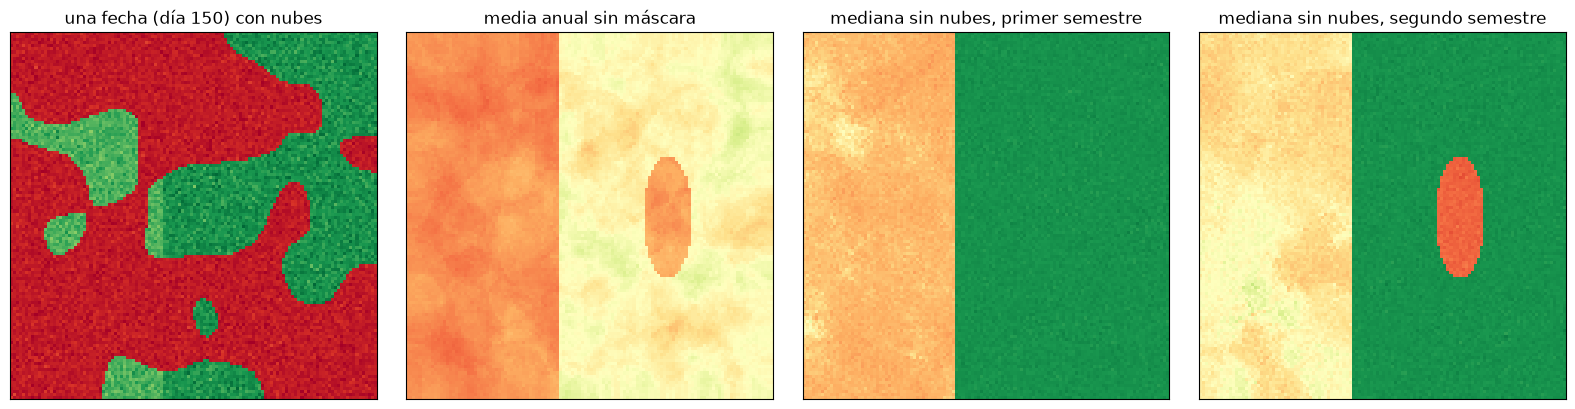

In [2]:
enmascarado = np.where(nubes, np.nan, observado)
periodos = {'primer semestre': dias < 180, 'segundo semestre': dias >= 180}
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(observado[30], cmap='RdYlGn', vmin=0, vmax=0.9); axs[0].set_title(f'una fecha (día {dias[30]}) con nubes')
axs[1].imshow(np.nanmean(observado, axis=0), cmap='RdYlGn', vmin=0, vmax=0.9); axs[1].set_title('media anual sin máscara')
for a, (nom, sel) in zip(axs[2:], periodos.items()):
    a.imshow(np.nanmedian(enmascarado[sel], axis=0), cmap='RdYlGn', vmin=0, vmax=0.9); a.set_title(f'mediana sin nubes, {nom}')
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

El compuesto del segundo semestre muestra la cicatriz del deslizamiento, que no existía en el primero. La diferencia entre los dos compuestos es un método sencillo y robusto de detección de cambios, el mismo que se usa para inventariar deslizamientos después de un evento de lluvias o un sismo. Las series de tiempo de píxeles individuales muestran además la fenología de los cultivos y el momento del cambio.

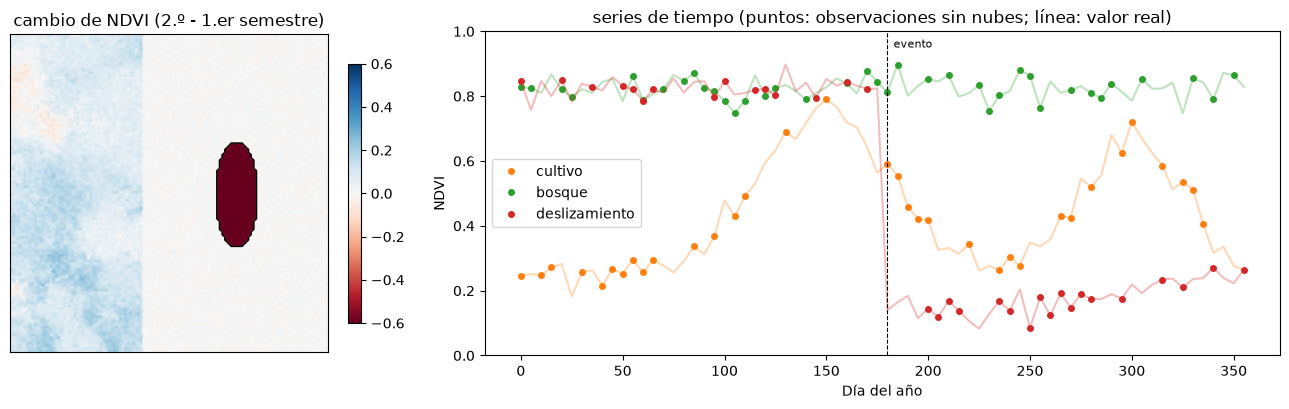

Área detectada como pérdida de vegetación: 4.93 ha (real 4.93 ha, con píxeles de 10 m)


In [3]:
dif = np.nanmedian(enmascarado[dias >= 180], 0) - np.nanmedian(enmascarado[dias < 180], 0)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 2]})
h = axs[0].imshow(dif, cmap='RdBu', vmin=-0.6, vmax=0.6); axs[0].contour(dif < -0.4, [0.5], colors='k', linewidths=1)
axs[0].set_title('cambio de NDVI (2.º - 1.er semestre)'); axs[0].set_xticks([]); axs[0].set_yticks([]); fig.colorbar(h, ax=axs[0], shrink=0.8)
for (fy, fx), nom, col in [((60, 20), 'cultivo', 'tab:orange'), ((20, 100), 'bosque', 'tab:green'), ((60, 85), 'deslizamiento', 'tab:red')]:
    serie = enmascarado[:, fy, fx]
    axs[1].plot(dias, cubo[:, fy, fx], color=col, alpha=0.3)
    axs[1].plot(dias, serie, 'o', color=col, ms=4, label=nom)
axs[1].axvline(180, color='k', ls='--', lw=0.8); axs[1].text(183, 0.95, 'evento', fontsize=8)
axs[1].set_xlabel('Día del año'); axs[1].set_ylabel('NDVI'); axs[1].legend(); axs[1].set_ylim(0, 1)
axs[1].set_title('series de tiempo (puntos: observaciones sin nubes; línea: valor real)')
plt.tight_layout(); plt.show()
area = (dif < -0.4).sum() * 10 * 10 / 1e4
print(f'Área detectada como pérdida de vegetación: {area:.2f} ha (real {desliz.sum()*100/1e4:.2f} ha, con píxeles de 10 m)')

## Google Earth Engine

Google Earth Engine {cite}`gorelick2017` combina un catálogo de varios petabytes (Landsat completo, Sentinel-1, 2, 3 y 5P, MODIS, modelos de elevación, datos climáticos y muchos más) con un motor de cálculo distribuido. El usuario escribe un programa en JavaScript, en el editor de código, o en Python, con la biblioteca `earthengine-api` y paquetes como `geemap`, y el cálculo se hace en los servidores de Google; solo se descargan los resultados. Es gratuito para uso académico y no comercial, con una cuenta y un proyecto de Google Cloud registrados.

Las operaciones del ejemplo anterior se escriben en Earth Engine casi igual. El fragmento siguiente, que no se ejecuta en este libro porque requiere autenticación, construye el compuesto de mediana de Sentinel-2 sin nubes para el Valle de Aburrá y calcula el NDVI:

```python
import ee
ee.Initialize(project='mi-proyecto')

aburra = ee.Geometry.Rectangle([-75.72, 6.05, -75.45, 6.40])

def enmascarar_nubes(img):
    scl = img.select('SCL')
    validos = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))   # sombra, nubes y cirros
    return img.updateMask(validos).divide(10000)

s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(aburra)
      .filterDate('2024-01-01', '2024-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
      .map(enmascarar_nubes))

mediana = s2.median().clip(aburra)
ndvi = mediana.normalizedDifference(['B8', 'B4']).rename('NDVI')
print(ndvi.reduceRegion(ee.Reducer.mean(), aburra, 20).getInfo())
```

## openEO y el ecosistema Copernicus

openEO {cite}`schramm2021` es una interfaz abierta y estándar para procesar cubos de datos en distintos proveedores en la nube, de modo que el mismo programa funciona en varios servicios. El Copernicus Data Space Ecosystem (CDSE), la plataforma oficial de los datos Copernicus, ofrece un navegador de imágenes (Copernicus Browser), un servicio openEO, la API de Sentinel Hub con su constructor de peticiones (Request Builder) y un entorno JupyterLab con los datos montados. El fragmento equivalente en openEO es:

```python
import openeo
con = openeo.connect('openeo.dataspace.copernicus.eu').authenticate_oidc()

cubo = con.load_collection(
    'SENTINEL2_L2A',
    spatial_extent={'west': -75.72, 'south': 6.05, 'east': -75.45, 'north': 6.40},
    temporal_extent=['2024-01-01', '2024-12-31'],
    bands=['B04', 'B08', 'SCL'])
scl = cubo.band('SCL')
nubes = (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)
cubo = cubo.filter_bands(['B04', 'B08']).mask(nubes)
ndvi = cubo.ndvi(red='B04', nir='B08').reduce_dimension(dimension='t', reducer='median')
ndvi.download('ndvi_aburra_2024.tif')
```

Los dos programas expresan la misma secuencia: seleccionar una colección, filtrarla en el espacio y el tiempo, enmascarar las nubes, reducir la dimensión temporal y calcular un índice. Esa es la forma de pensar que este capítulo busca transmitir, más que la sintaxis de una plataforma particular, que cambia con frecuencia.

## Otras plataformas

Microsoft Planetary Computer y Amazon Web Services publican los mismos archivos (Landsat, Sentinel) como objetos en la nube con catálogos STAC, que se leen directamente desde Python con `pystac-client` y `stackstac` u `odc-stac` y se procesan con `xarray` y `dask`. Open Data Cube es un programa libre para montar cubos de datos propios, que usan varias agencias nacionales. Las plataformas comerciales, como Planet o Sentinel Hub, ofrecen imágenes de mayor resolución o mayor frecuencia y servicios de procesamiento por suscripción.

## Para profundizar

{cite:t}`gorelick2017` describe la arquitectura de Earth Engine; {cite:t}`schramm2021`, la de openEO; y {cite:t}`mahecha2020`, el concepto de cubo de datos del sistema Tierra. Las lecturas recomendadas sobre plataformas de la página del curso comparan las opciones disponibles. Los tutoriales del curso de Google Earth Engine, Copernicus Browser, Request Builder y JupyterLab de CDSE se listan en el apéndice {doc}`A_Practicas`.